# Smart Parking Availability Predictor - Part 1: Data Cleaning & EDA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

**Academic Year:** 2026-27 | **Evaluation Rubric:** Part 1 (3 Marks)

This notebook demonstrates:
1. Ingestion of the authentic UCI Parking Birmingham dataset (30 car parks, Oct-Dec 2016).
2. Cleaning missing values, negative occupancies, and overflow readings.
3. Engineering past-only temporal, lag, and rolling features per car park.
4. Strict chronological train-validation-test partitioning (70% / 15% / 15%) eliminating future data leakage.
5. Exploratory Data Analysis (EDA) of occupancy patterns by hour, weekday, and facility.

In [1]:
# Setup Cell: Add root to sys.path and import libraries
import os
import sys
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
print('Environment configured successfully!')

Environment configured successfully!


In [2]:
# Load raw Birmingham dataset
raw_data_path = 'data/raw/dataset.csv' if os.path.exists('data/raw/dataset.csv') else '../data/raw/dataset.csv'
df_raw = pd.read_csv(raw_data_path)
print(f'Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print('Unique Car Parks:', df_raw['SystemCodeNumber'].nunique())
df_raw.head()

Raw Dataset Shape: 35,717 rows x 4 columns
Unique Car Parks: 30


,SystemCodeNumber,Capacity,Occupancy,LastUpdated
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48


In [3]:
# Preprocess, engineer features and split chronologically
from src.preprocess import load_and_clean_data, engineer_features, split_chronologically

df_clean = load_and_clean_data(raw_data_path)
df_features = engineer_features(df_clean)
train_df, val_df, test_df = split_chronologically(df_features)

print('\nClass Distribution in Training Set:')
print(train_df['target_class'].value_counts(normalize=True).round(4) * 100)

Loaded raw dataset from ../data/raw/dataset.csv with 35,717 records.
Removed 216 duplicate readings.
Cleaned dataset shape: 35,501 rows x 5 columns.


Features engineered. Final usable dataset: 35,381 records.



Chronological split summary:
  Train: 24,766 rows (2016-10-04 09:25:48 to 2016-11-26 08:28:01)
  Val:   5,307 rows (2016-11-26 08:28:01 to 2016-12-08 15:26:23)
  Test:  5,308 rows (2016-12-08 15:26:23 to 2016-12-19 16:03:35)

Class Distribution in Training Set:
target_class
Available      54.78
Nearly Full    29.89
Full           15.33
Name: proportion, dtype: float64


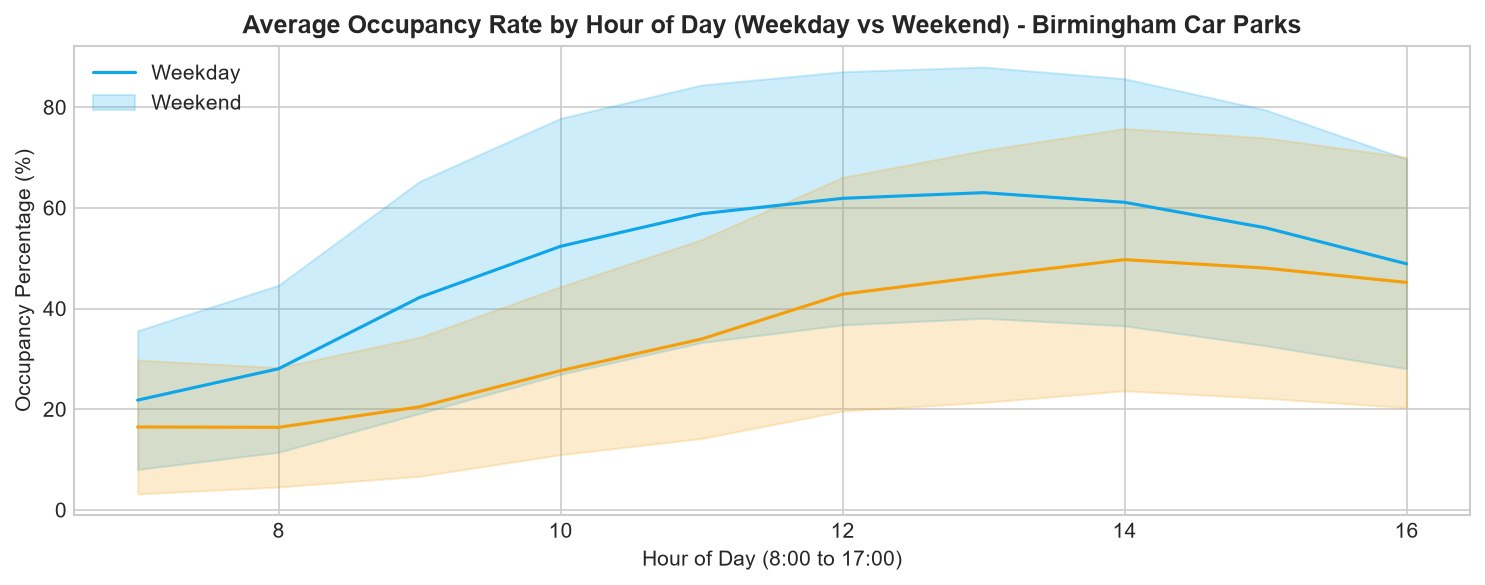

In [4]:
# Visualizing Diurnal Parking Occupancy Pattern (08:00 - 17:00)
plt.figure(figsize=(10, 4), dpi=150)
sns.lineplot(data=train_df, x='hour', y='occupancy_pct', hue='is_weekend', errorbar='sd', palette=['#0ea5e9', '#f59e0b'])
plt.title('Average Occupancy Rate by Hour of Day (Weekday vs Weekend) - Birmingham Car Parks', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (8:00 to 17:00)', fontsize=10)
plt.ylabel('Occupancy Percentage (%)', fontsize=10)
plt.legend(['Weekday', 'Weekend'], loc='upper left')
plt.tight_layout()
plt.show()

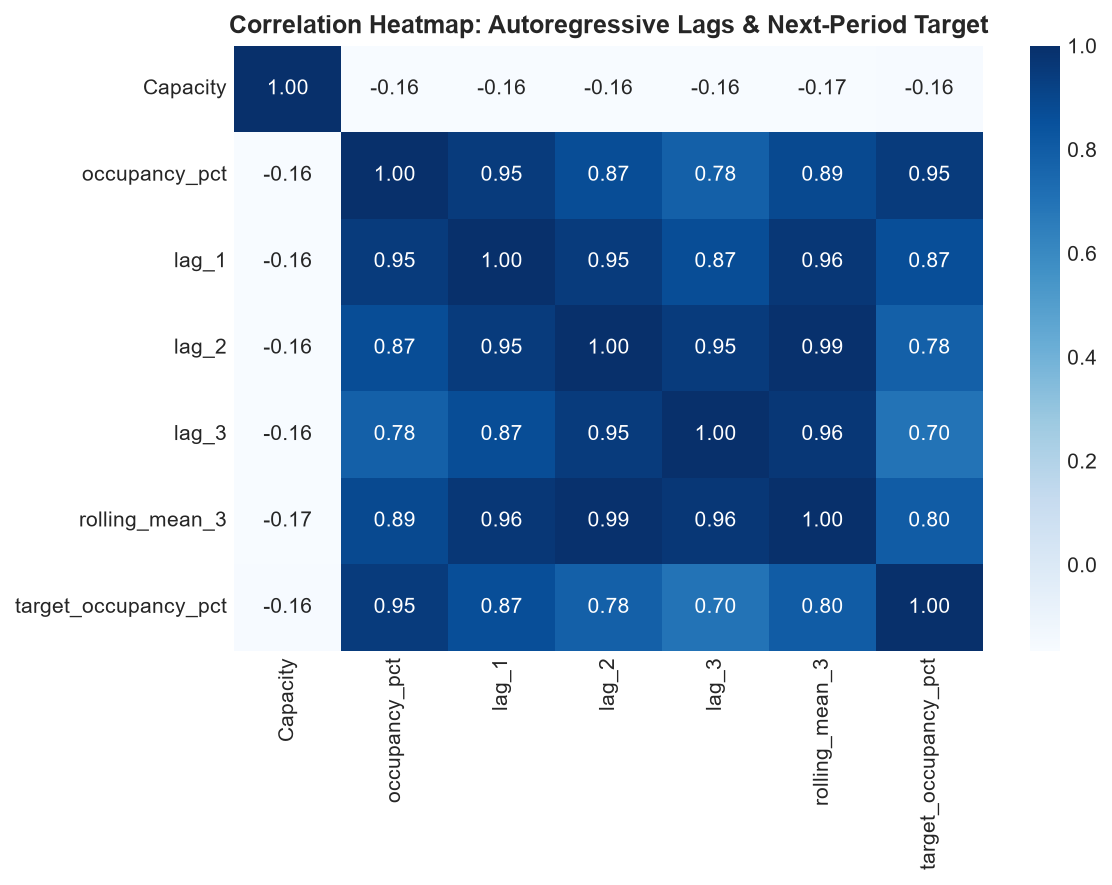

In [5]:
# Visualizing Correlation Heatmap of Engineered Features
corr_cols = ['Capacity', 'occupancy_pct', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'target_occupancy_pct']
plt.figure(figsize=(8, 6), dpi=150)
sns.heatmap(train_df[corr_cols].corr(), annot=True, fmt='.2f', cmap='Blues', cbar=True)
plt.title('Correlation Heatmap: Autoregressive Lags & Next-Period Target', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_45200\3820712652.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='target_class', order=['Available', 'Nearly Full', 'Full'], palette=['#10b981', '#f59e0b', '#ef4444'])


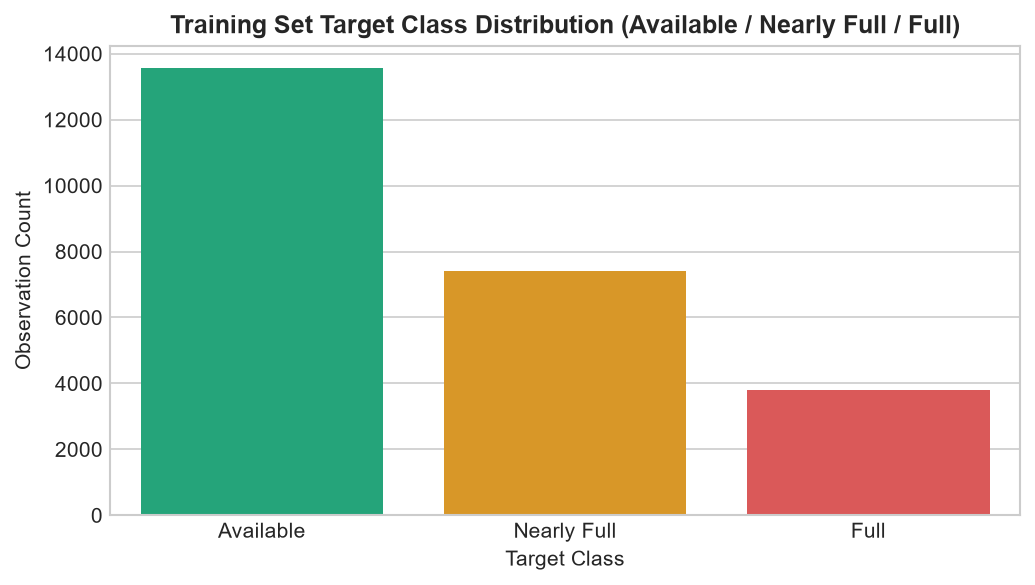

In [6]:
# Visualizing Class Distribution
plt.figure(figsize=(7, 4), dpi=150)
sns.countplot(data=train_df, x='target_class', order=['Available', 'Nearly Full', 'Full'], palette=['#10b981', '#f59e0b', '#ef4444'])
plt.title('Training Set Target Class Distribution (Available / Nearly Full / Full)', fontsize=12, fontweight='bold')
plt.xlabel('Target Class', fontsize=10)
plt.ylabel('Observation Count', fontsize=10)
plt.tight_layout()
plt.show()